In [1]:
from gammapy.data import DataStore, EventList, Observations, Observation
from gammapy.maps import MapAxis, RegionGeom, RegionNDMap
from gammapy.datasets import (
    SpectrumDataset,
    Datasets,
    FluxPointsDataset
)
from gammapy.modeling.models import (
    PowerLawSpectralModel,
    SkyModel
)
from gammapy.makers import (
    ReflectedRegionsBackgroundMaker,
    SafeMaskMaker,
    SpectrumDatasetMaker,
)
from gammapy.modeling import Fit
from gammapy.estimators import FluxPointsEstimator

from basil.datasets_basil import SpectrumDatasetOnOffBASiL
from basil.utils import basil_factors


import numpy as np
from matplotlib import pyplot as plt
from astropy.coordinates import SkyCoord, Angle
import astropy.units as u
from regions import CircleSkyRegion
import pickle
import os
import math
from pathlib import Path


# Contents

This notebook presents the steps for performing a 1D spectral analysis with BASiL in Gammapy. 
It utilizes IRFs from the public test data release from H.E.S.S., as distributed alongside Gammapy (see docs.gammmapy.org, Getting started).

The event lists were generated by Monte Carlo and fake GAMMANESS and likelihood values were created just for this example.
The user must provide its own data and attribute likelihood values to the measured events.

Suggested folder structure:

```
project_folder/
└── run_<ID>/
    └── basil_factors/
        └── likelihoods/

```

It may be necessary to change the path in all uses of `file_path` if adapted otherwise.

**Summary**:

I) Dataset creation.

II) Significance.

III) Model fitting and spectra.


# I) Dataset creation - Joint analysis

1) SpectrumDatasetOnOff is created normally, once observations, geometry and safe masks are defined.
2) SpectrumDatasetOnOffBASiL is created from SpectrumDatasetOnOff, including event information.
3) Event likelihoods are computed based on distributions of gamma and background events.

## Loading observations and creating the SpectrumDatasetOnOff datasets

 - Set GAMMAPY_DATA to `/gammapy-datasets/` path, where `hess-dl3-dr1` folder is located.


In [5]:
%env GAMMAPY_DATA= #Set the path to gammapy-data

env: GAMMAPY_DATA=#Set the path to gammapy-data


In [3]:
project_folder = './example_data/Point'

In [16]:
# Load observations
obs_ids = [23523, 23526, 23559, 23592]
datastore = DataStore.from_dir("$GAMMAPY_DATA/hess-dl3-dr1/")
observations_ = datastore.get_observations(obs_ids, required_irf=["aeff", "edisp", "psf"])

# Create new observations with replacement event lists
observations = Observations()

for obs in observations_:
    obs_id = obs.obs_id
    events = EventList.read(project_folder+"/run{:}/events_fake_run{:}.fits".format(obs_id, obs_id))
    new_obs = obs.copy(events=events, in_memory=True)
    observations.append(new_obs)

In [41]:
pos = observations[0].meta.target.position
ra_obj = pos.icrs.ra.value
dec_obj = pos.icrs.dec.value
name_obj = 'Crab'
target = SkyCoord(ra_obj, dec_obj, frame='icrs', unit='deg')

e_reco = np.logspace(-1, 2, 13) * u.TeV 
e_true = np.logspace(-1, 2, 49) * u.TeV 

energy_axis = MapAxis.from_edges(e_reco, unit='TeV', name='energy', interp='log')
energy_axis_true = MapAxis.from_edges(e_true, unit='TeV', name="energy_true", interp='log')

offset_max = 2*u.deg

target_position = pos
on_region_radius = Angle("0.1118034 deg")
on_region = CircleSkyRegion(center=target_position, radius=on_region_radius)

geom = RegionGeom.create(region=on_region, axes=[energy_axis])
dataset_empty = SpectrumDataset.create(geom=geom, energy_axis_true=energy_axis_true)

dataset_maker = SpectrumDatasetMaker(
    containment_correction=True, selection=["counts", "exposure", "edisp"]
)
bkg_maker = ReflectedRegionsBackgroundMaker()
safe_mask_maker = SafeMaskMaker(
                       methods=["offset-max", 'aeff-max', 'edisp-bias'],
                       offset_max=offset_max, bias_percent=10, aeff_percent=10)

datasets = Datasets()
for obs_id, observation in zip(obs_ids, observations):
    dataset = dataset_maker.run(dataset_empty.copy(name=str(obs_id)), observation)
    dataset_on_off = bkg_maker.run(dataset, observation)
    dataset_on_off = safe_mask_maker.run(dataset_on_off, observation)
    datasets.append(dataset_on_off)
    print('Ethreshold bin: {:}'.format(np.argwhere(dataset_on_off.mask_safe.data == True)[0][0]))

stacked = datasets.stack_reduce()

Ethreshold bin: 4
Ethreshold bin: 4
Ethreshold bin: 4
Ethreshold bin: 4


In [42]:
# Suggested folder structure
for i in range(len(datasets)):
    run = datasets[i].name
    file_path = project_folder+'/run{:}'.format(run)+'/basil_factors'
    os.makedirs(file_path, exist_ok=True)
    os.makedirs(file_path+"/likelihoods/", exist_ok=True)

## Creating SpectrumDatasetOnOffBASiL datasets

In [43]:
datasets_basil = Datasets()
for m in range(len(obs_ids)):
    dataset_on_off = datasets[m]
    run = dataset_on_off.name
    
    ### Change if necessary ###
    file_path = project_folder+'/run{:}'.format(run)+'/basil_factors'
    ###########################
    
    events = EventList.read(project_folder+"/events_fake_run{:}.fits".format(run))
    
    # Initialize BASiL Spectrum Dataset On/Off
    dataset_onoff_basil = SpectrumDatasetOnOffBASiL(name=dataset_on_off.name)
    dataset_onoff_basil.counts = dataset_on_off.counts
    dataset_onoff_basil.counts_off = dataset_on_off.counts_off
    dataset_onoff_basil.exposure = dataset_on_off.exposure
    dataset_onoff_basil.acceptance = dataset_on_off.acceptance
    dataset_onoff_basil.acceptance_off = dataset_on_off.acceptance_off
    dataset_onoff_basil.gti = dataset_on_off.gti
    dataset_onoff_basil.mask_fit = dataset_on_off.mask_fit
    dataset_onoff_basil.psf = dataset_on_off.psf
    dataset_onoff_basil.edisp = dataset_on_off.edisp
    dataset_onoff_basil.mask_safe = dataset_on_off.mask_safe
    dataset_onoff_basil.meta_table = dataset_on_off.meta_table

    # Values
    energy = dataset_onoff_basil.counts.geom.axes["energy"].center.value
    Non = dataset_onoff_basil.counts.data
    
    # Identify the events inside the On region
    # Construct the res list from EventList
    energy_axis = dataset_onoff_basil.counts.geom.axes["energy"]
    en_bins = energy_axis.edges.value
    on_region_radius = Angle("0.1118034 deg") # HESS default is 0.118
    theta = events.radec.separation(pos)
    on_mask = np.argwhere(theta.value <= on_region_radius.value)

    event_en = events.table['ENERGY'][on_mask].value.flatten()
    events_zeta = events.table['GAMMANESS'][on_mask].value.flatten() 
    event_var = []
    for i in range(len(Non)):
        mask_en = np.argwhere((event_en > en_bins[i]) & (event_en < en_bins[i+1])).flatten()
        if len(mask_en) == 0:
            event_var.append([])
        else:
            event_var.append(events_zeta[mask_en].flatten())
    
    with open(file_path+'/event_variable_run'+str(run)+'.pkl', 'wb') as h:
        pickle.dump(event_var, h, pickle.HIGHEST_PROTOCOL)
    
    datasets_basil.append(dataset_onoff_basil)
    

In [ ]:
'''
    Suggested approach to obtain the event likelihoods based on binned distributions.
    Code does not work as it stands!
    It requires binned and normalized distributions of gamma and background events for each energy bin.
    
    If more than one gamma-hadron separation variable, the likelihoods must be combined 
    (e.g. multiplied if independent)

'''

def compute_like_events(n_on, event_var_bin, density_sig, points_sig, density_bkg, points_bkg):
    """
       Template for attributing likelihood values based on binned distributions. 
    """

    like_bkg = np.array([])
    like_sig = np.array([])

    for j in range(n_on):
        # Find where in the histogram is the var_Non[j] value is and find the density value
        if np.argwhere(points_sig < event_var_bin[j]).size > 1:
            indx_sig = np.argwhere(points_sig < event_var_bin[j])[-1][0]
            if (indx_sig == len(density_sig)): #border case
                indx_sig -= 1
        else:
            indx_sig = 0
            
        # Repeat for background distribution
        if np.argwhere(points_bkg < event_var_bin[j]).size > 1:
            indx_bkg = np.argwhere(points_bkg < event_var_bin[j])[-1][0]
            if (indx_bkg == len(density_bkg)):
                indx_bkg -= 1
        else:
            indx_bkg = 0
            
        like_sig = np.append(like_sig, sig_density)
        like_bkg = np.append(like_bkg, bkg_density)

    return like_sig, like_bkg


for j in range(len(datasets_basil)):
    run = datasets_basil[j].name
    ### Change if necessary ###
    file_path = project_folder+'/run{:}'.format(run)+'/basil_factors'
    ###########################
    
    n_on = datasets_basil[j].counts.data.flatten()
    energy = datasets_basil[j].counts.geom.axes["energy"].center.value
    
    for i in range(len(n_on)):
        if n_on[i][0][0] > 0:
            density_bkg, points_bkg = np.histogram(distribution_bkg, bins=binning_bkg, density=True)
            density_sig, points_sig = np.histogram(distribution_gamma, bins=binning_gamma, density=True)
    
            like_sig, like_bkg = compute_like_events(int(n_on[i]), np.array(event_var[i]), density_sig, points_sig, density_bkg, points_bkg)
        else:
            like_sig = np.ones(int(n_on[i]))
            like_bkg = np.ones(int(n_on[i]))

        with open(file_path+'/likelihoods/likelihood_gamma_bin'+str(energy[i])+'.pkl', 'wb') as h:
            pickle.dump(like_sig, h, pickle.HIGHEST_PROTOCOL)
        with open(file_path+'/likelihoods/likelihood_bkg_bin'+str(energy[i])+'.pkl', 'wb') as h:
            pickle.dump(like_bkg, h, pickle.HIGHEST_PROTOCOL)


# Computing BASiL factors

Reading likelihood values and computing the logarithm of the combinatorial factors. Result (`logprod`) is attributed as a dictionary to each dataset.


In [49]:
for i in range(len(datasets_basil)):
    run = datasets_basil[i].name
    ### Change if necessary ###
    file_path = project_folder+'/run{:}'.format(run)+'/basil_factors'
    likelihood_dir = Path(file_path) / "likelihoods"
    ###########################
    
    energy = datasets_basil[i].counts.geom.axes["energy"].center.value
    
    like_sig_list = []
    like_bkg_list = []
    for en in energy:
        file_name = likelihood_dir / f"likelihood_gamma_bin{en}.pkl"
        try:
            with file_name.open("rb") as file:
                likesig = pickle.load(file)
            like_sig_list.append(likesig)
        except Exception as exc:
            print(f"Could not load {file_name}: {exc}")
            like_sig_list.append([])
        file_name = likelihood_dir / f"likelihood_bkg_bin{en}.pkl"
        try:
            with file_name.open("rb") as file:
                likebkg = pickle.load(file)
            like_bkg_list.append(likebkg)
        except Exception as exc:
            print(f"Could not load {file_name}: {exc}")
            like_bkg_list.append([])


    
    basil_class = basil_factors(n_on=datasets_basil[i].counts.data, n_off=datasets_basil[i].counts_off.data, alpha=datasets_basil[i].alpha.data, energy=energy)
    basil_class.run(like_sig_list, like_bkg_list, file_path)
    
    dict_logprod = {}
    for en in energy:
        with open(file_path+'/prod_bin'+str(en)+'.pkl', 'rb') as file:
            logprod = pickle.load(file)
        dict_logprod[str(en)] = logprod

    datasets_basil[i].dict_logprod = dict_logprod
    

# Dataset creation - stacked analysis

Likelihoods computed for joint analysis are stacked considering the energy safe mask range.
BASiL factors are computed from the new likelihood arrays.

In [12]:
# Create stacked list of zeta-BDT values

file_path_stacked = project_folder+'/stacked/'

# Compute likelihood lists
energy_axis = datasets_basil[0].counts.geom.axes["energy"]
energy = energy_axis.center.value
for i in range(len(datasets_basil)):
    run = datasets_basil[i].name
    
    ### Change if necessary ###
    file_path = project_folder+'/run{:}'.format(run)+'/basil_factors'
    ###########################

    like_gamma_list = []
    like_bkg_list = []
    for j in range(len(energy)):
        like_gamma_list.append([])
        like_bkg_list.append([])
        
        with open(file_path+'/likelihoods/likelihood_gamma_bin'+str(energy[j])+'.pkl', 'rb') as file:
            like_gamma = pickle.load(file)

        with open(file_path+'/likelihoods/likelihood_bkg_bin'+str(energy[j])+'.pkl', 'rb') as file:
            like_bkg = pickle.load(file)
        
        if len(like_gamma) > 0:
            for k in range(len(like_gamma)):
                like_gamma_list[j].append(like_gamma[k])
                like_bkg_list[j].append(like_bkg[k])

    # Save likelihood list
    with open(file_path+'/likelihoods/likelihood_gamma_list_run'+str(run)+'.pkl', 'wb') as h:
        pickle.dump(like_gamma_list, h, pickle.HIGHEST_PROTOCOL)
    with open(file_path+'/likelihoods/likelihood_bkg_list_run'+str(run)+'.pkl', 'wb') as h:
        pickle.dump(like_bkg_list, h, pickle.HIGHEST_PROTOCOL)

        
### Stack likelihoods 
# Initialization with first run
run = datasets_basil[0].name
### Change if necessary ###
file_path = project_folder+'/run{:}'.format(run)+'/basil_factors'
###########################
with open(file_path+'/likelihoods/likelihood_gamma_list_run'+str(run)+'.pkl', 'rb') as file:
    like_gamma_list = pickle.load(file)
with open(file_path+'/likelihoods/likelihood_bkg_list_run'+str(run)+'.pkl', 'rb') as file:
    like_bkg_list = pickle.load(file)
    
# Apply energy threshold mask    
i = 0
while datasets_basil[0].mask_safe.data[i][0][0] == False:
    like_gamma_list[i] = []
    like_bkg_list[i] = []
    i += 1    
    
# Append other runs
for i in range(1,len(datasets_basil)):
    run = datasets_basil[i].name
    ### Change if necessary ###
    file_path = project_folder+'/run{:}'.format(run)+'/basil_factors'
    ###########################
    with open(file_path+'/likelihoods/likelihood_gamma_list_run'+str(run)+'.pkl', 'rb') as file:
        res = pickle.load(file)
    with open(file_path+'/likelihoods/likelihood_bkg_list_run'+str(run)+'.pkl', 'rb') as file:
        res_bkg = pickle.load(file)
    # Apply energy threshold mask 
    k = 0
    while datasets_basil[i].mask_safe.data[k][0][0] == False:
        res[k] = []
        res_bkg[k] = []
        k += 1
    for j in range(len(res)):
        if len(like_gamma_list[j]) == 0:
            if len(res[j]) > 0:
                like_gamma_list[j] = res[j]
                like_bkg_list[j] = res_bkg[j]
        else: # there is data in res_stack
            if len(res[j]) > 0:
                like_gamma_list[j] = np.append(like_gamma_list[j], res[j])
                like_bkg_list[j] = np.append(like_bkg_list[j], res_bkg[j])

# Save res
with open(file_path_stacked+'/likelihood_gamma_list_stacked.pkl', 'wb') as h:
    pickle.dump(like_gamma_list, h, pickle.HIGHEST_PROTOCOL)
with open(file_path_stacked+'/likelihood_bkg_list_stacked.pkl', 'wb') as h:
    pickle.dump(like_bkg_list, h, pickle.HIGHEST_PROTOCOL)


#-------------
# Compute factors - Stacked analysis
basil_class = basil_factors(n_on=stacked.counts.data, n_off=stacked.counts_off.data, alpha=stacked.alpha.data, energy=energy_axis.center.value)
basil_class.run(like_gamma_list, like_bkg_list,file_path_stacked)

In [15]:
# Stacked Analysis
stacked_basil = SpectrumDatasetOnOffBASiL(name='stacked')
# Include information from standard dataset
stacked_basil.counts = stacked.counts
stacked_basil.counts_off = stacked.counts_off  
stacked_basil.exposure = stacked.exposure
stacked_basil.acceptance = stacked.acceptance
stacked_basil.acceptance_off = stacked.acceptance_off
stacked_basil.gti = stacked.gti
stacked_basil.mask_fit = stacked.mask_fit
stacked_basil.psf = stacked.psf
stacked_basil.edisp = stacked.edisp
stacked_basil.mask_safe = stacked.mask_safe
stacked_basil.meta_table = stacked.meta_table


dict_logprod = {}
for j in range(len(energy)):
    with open(file_path_stacked+'/prod_bin'+str(energy[j])+'.pkl', 'rb') as file:
        logprod = pickle.load(file)
    dict_logprod[str(energy[j])] = logprod

stacked_basil.dict_logprod = dict_logprod


# II) Significance 

In [ ]:
# Compute per energy bin and overall detection

In [ ]:
# Detection significance considering all energies

like_sig_all = np.array([])
like_bkg_all = np.array([])
for i in range(len(basil_class.n_on)):
    energy_ = (basil_class.energy[i]*dataset_onoff_basil.mask_safe.data[i])[0][0]
    if energy_ > 0:
        with open('/home/matheus/Documents/BASiL/dist/factors/'+label+'/likelihoods/likelihood_gamma_bin'+str(energy_)+'.pkl', 'rb') as file:
           like_sig = pickle.load(file)
        with open('/home/matheus/Documents/BASiL/dist/factors/'+label+'/likelihoods/likelihood_bkg_bin'+str(energy_)+'.pkl', 'rb') as file:
           like_bkg = pickle.load(file)
        
        like_sig_all = np.append(like_sig_all, like_sig)
        like_bkg_all = np.append(like_bkg_all, like_bkg)
    

In [ ]:
# Better still to add as a method in basil_factors 
# logBF_pre = basil_class_all.compute_BF(like_sig_all, like_bkg_all)
# Add another method that computes the significance
# signficance = basil_class_all.compute_significance(like_sig_all, like_bkg_all, sig_max)

basil_class = basil_factors(n_on=Non_all, n_off=Noff_all, alpha=alpha_all, energy=energy_axis.center.value)
logfactor_all = basil_class.compute_log_factor(Non_all, Noff_all, alpha_all)
logcomb_all = basil_class.combinatory_log(like_bkg_all, like_sig_all):
logprod_all = np.array(logcomb_all) + np.array(logfactor_all)
logcomb_all = combinatory_log(like_bkg_all, like_sig_all)

xs = logprod_all + np.stack([math.lgamma(n+1) for n in range(len(logprod_all))])
logBF_pre = math.lgamma(Noff_all+1) - math.lgamma(Non_all+Noff_all+1) - logcomb_all[0] + log_sum_P_sN_mod(xs)
    

In [ ]:
# Posterior with credible interval

In [ ]:
# Plot posterior probability with credible interval

def find_peak(x,interp):
    return interp(x)

from scipy.optimize import minimize

max_sig = [20,20,20,20,300,300,80, 60, 50,50,30,30]
mu_sig = dataset_onoff_basil.npred_signal().data
yinf_arr = np.array([])
ysup_arr = np.array([])
max_posterior = np.array([])
sig_basil = np.array([])
for k in range(len(energy)):
    sig_array = 10**np.linspace(np.log10(0.01),np.log10(max_sig[k]),3000)
    en_bin = k
    pos_basil = np.array([])
    for j in sig_array:    
        for i in range(len(mu_sig)):
            mu_sig[i][0][0] = j
        basil = basil_like_general_v5(dataset_onoff_basil.counts.data, mu_sig, energy, dataset_onoff_basil.dict_logprod)
        pos_basil = np.append(pos_basil, basil[en_bin][0][0])

    #interp = interp1d(sig_array, np.exp(-pos_basil/2))
    fig, ax = plt.subplots()
    #prob_s_new = interp(sig_array)
    x_inf, x_sup, y_inf, y_sup = hpd_interval(sig_array, np.exp((-pos_basil+min(pos_basil))/2), 0.6827)
    yinf_arr = np.append(yinf_arr, y_inf)
    ysup_arr = np.append(ysup_arr, y_sup)
    max_posterior = np.append(max_posterior, max(np.exp((-pos_basil+min(pos_basil))/2)))
    ax.plot(sig_array, np.exp((-pos_basil+min(pos_basil))/2))
    ax.fill_between(x=sig_array, y1= np.exp((-pos_basil+min(pos_basil))/2),where= (x_inf < sig_array)&(sig_array < x_sup),color= "b", alpha= 0.5)
    plt.hlines(y_inf, min(sig_array), max(sig_array), ls='dashed', color='black', lw=1)
    plt.hlines(y_sup, min(sig_array), max(sig_array), ls='dotted', color='black', lw=1)
    plt.xlabel('Expected average signal', fontsize=15)
    plt.ylabel('Posterior distribution', fontsize=15)
    
    
    interp = interp1d(sig_array, pos_basil, kind='cubic', bounds_error=False, fill_value=0)
    res_min = minimize(find_peak, 3, args=(interp), bounds=[(0, None)])
    plt.vlines(res_min.x[0], 0, 1, color='black')
    sig_basil = np.append(sig_basil, res_min.x[0])
    #plt.savefig("./Sources/Crab/theta2_psf/posterior/posterior_credible-interval_en{:.4f}".format(energy[en_bin])+'.png', dpi=200, bbox_inches='tight')
    plt.close()
    

In [ ]:
# Significance of eachh flux point
label_factors = 'crab/theta2_psf'
energy = energy_axis.center.value
logBF_pre_arr = np.array([])
logcomb0_arr = np.array([])
Non_arr = np.array([])
Noff_arr = np.array([])
# Open log-prod
for i in range(len(energy)):
    with open('/home/matheus/Documents/BASiL/dist/factors/'+label_factors+'/prod_bin'+str(energy[i])+'.pkl', 'rb') as h:
         logprod = pickle.load(h)   

    with open('/home/matheus/Documents/BASiL/dist/factors/'+label_factors+'/comb_bin'+str(energy[i])+'.pkl', 'rb') as h:
         logcomb = pickle.load(h)   

    Non = dataset_onoff_basil.counts.data[i][0][0]
    Noff = dataset_onoff_basil.counts_off.data[i][0][0]
    
    xs = logprod + np.stack([math.lgamma(n+1) for n in range(len(logprod))])
    
    logBF_pre = math.lgamma(Noff+1) - math.lgamma(Non+Noff+1) - logcomb[0] + log_sum_P_sN_mod(xs)
    
    logcomb0_arr = np.append(logcomb0_arr, logcomb[0])
    logBF_pre_arr = np.append(logBF_pre_arr, logBF_pre)
    Non_arr = np.append(Non_arr, Non)
    Noff_arr = np.append(Noff_arr, Noff)


In [ ]:

def significance_logBF_mod(logBF_pre, smax):
    logs_max = np.log(smax)
    logBF = logBF_pre - logs_max
    
    # sign of logprob moved to exponential below
    logprob = max(0, logBF) + math.log1p(math.exp(-abs(logBF)))

    if logprob < 700:  # safe range
        return norm.isf(math.exp(-logprob))
    else:
        t = np.sqrt(2 * logprob)
        return t - (np.log(t) + 0.5*np.log(2*np.pi)) / t

In [ ]:
significance_basil = np.array([])


smax = sig_basil*5
for indx in range(12):
    sig = significance_logBF_mod(logBF_pre_arr[indx], smax[indx])
    significance_basil = np.append(significance_basil, sig)
    print(sig)

# III) Model fit

## Joint

In [62]:
model = PowerLawSpectralModel(
    index=2.2,
    amplitude="1e-11 cm-2 s-1 TeV-1",
    reference="1 TeV",
)

crab_model_1_b = SkyModel(spectral_model=model,
                    name="crab_model")

datasets_basil.models = [crab_model_1_b]

fit = Fit()
result_fit_joint = fit.run(datasets=datasets_basil)

In [68]:
result_fit_joint

In [63]:
result_fit_joint.parameters.to_table()

type,name,value,unit,error,min,max,frozen,link,prior
str1,str9,float64,str14,float64,float64,float64,bool,str1,str1
,index,2.1808e+00,,7.254e-02,nan,nan,False,,
,amplitude,2.3356e-11,TeV-1 s-1 cm-2,2.421e-12,nan,nan,False,,
,reference,1.0000e+00,TeV,0.000e+00,nan,nan,True,,


## Stacked

In [18]:
model =  PowerLawSpectralModel(
    index=2.2,
    amplitude="1e-11 cm-2 s-1 TeV-1",
    reference="1 TeV",
)

crab_model_1_b = SkyModel(spectral_model=model,
                    name="crab_model_stacked")

stacked_basil.models = [crab_model_1_b]

fit = Fit()
result_fit_stacked = fit.run(datasets=stacked_basil)

In [69]:
result_fit_stacked

In [19]:
result_fit_stacked.parameters.to_table()

type,name,value,unit,error,min,max,frozen,link,prior
str1,str9,float64,str14,float64,float64,float64,bool,str1,str1
,index,2.1800e+00,,7.282e-02,nan,nan,False,,
,amplitude,2.3126e-11,TeV-1 s-1 cm-2,2.411e-12,nan,nan,False,,
,reference,1.0000e+00,TeV,0.000e+00,nan,nan,True,,


## Spectrum

In [66]:
e_reco = np.logspace(-1, 2, 13) * u.TeV 

fpe = FluxPointsEstimator(
    energy_edges=e_reco, source="crab_model", selection_optional="all",
)
flux_points_basil_joint = fpe.run(datasets=datasets_basil)

flux_points_dataset_joint = FluxPointsDataset(
    data=flux_points_basil_joint, models=datasets_basil.models
)

fpe = FluxPointsEstimator(
    energy_edges=e_reco, source="crab_model_stacked", selection_optional="all",
)

flux_points_basil_stacked = fpe.run(datasets=stacked_basil)

flux_points_dataset_stacked = FluxPointsDataset(
    data=flux_points_basil_stacked, models=stacked_basil.models
)



/home/matheus/miniconda3/envs/gammapy-1.3-test/lib/python3.11/site-packages/gammapy/datasets/core.py:240: RuntimeWarning: overflow encountered in scalar add
  stat_sum += dataset.stat_sum()
/home/matheus/miniconda3/envs/gammapy-1.3-test/lib/python3.11/site-packages/gammapy/datasets/core.py:240: RuntimeWarning: overflow encountered in scalar add
  stat_sum += dataset.stat_sum()
/home/matheus/miniconda3/envs/gammapy-1.3-test/lib/python3.11/site-packages/gammapy/datasets/core.py:240: RuntimeWarning: overflow encountered in scalar add
  stat_sum += dataset.stat_sum()
/home/matheus/miniconda3/envs/gammapy-1.3-test/lib/python3.11/site-packages/gammapy/datasets/core.py:240: RuntimeWarning: overflow encountered in scalar add
  stat_sum += dataset.stat_sum()
/home/matheus/miniconda3/envs/gammapy-1.3-test/lib/python3.11/site-packages/gammapy/datasets/core.py:240: RuntimeWarning: overflow encountered in scalar add
  stat_sum += dataset.stat_sum()


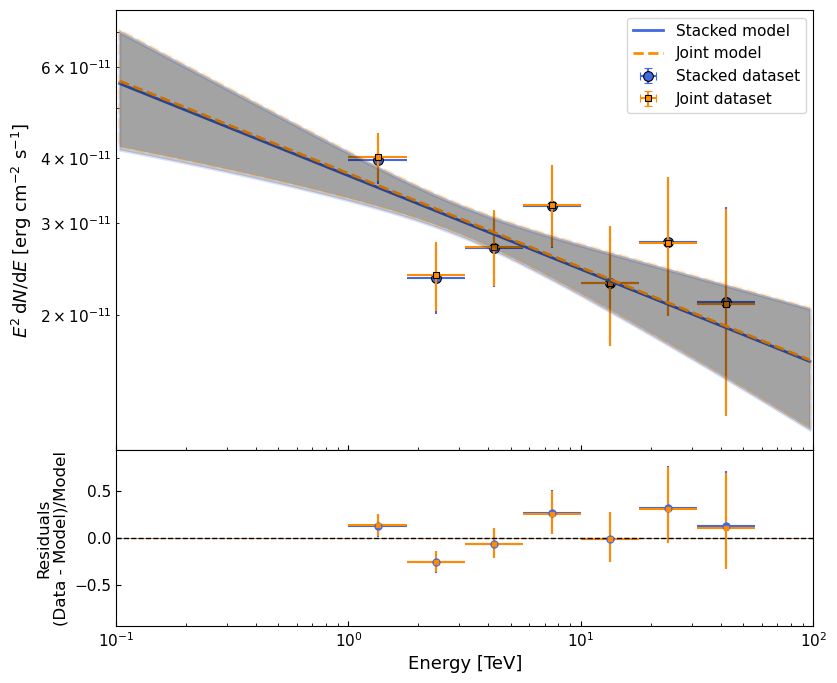

<Figure size 900x700 with 0 Axes>

In [67]:
### Plotting the spectra

# First dataset: stacked
kwargs_spectrum_stacked = {
    "kwargs_fp": {
        "color": "royalblue",
        "marker": "o",
        "markersize": 7,
        "markeredgecolor": "black",
        "markeredgewidth": 0.8,
        "ls": "none",
        "label": "Stacked dataset",
        "zorder": 5,
    },
    "kwargs_model": {
    "color": "royalblue",
    "ls": "-",
    "linewidth": 2,
    "label": "Stacked model",
    }
}

kwargs_residuals_stacked = {
    "color": "royalblue",
    "marker": "o",
    "markersize": 5,
    "ls": "none",
}

# Second dataset: joint
kwargs_spectrum_joint = {
    "kwargs_fp": {
        "color": "darkorange",
        "marker": "s",
        "markersize": 5,
        "markeredgecolor": "black",
        "markeredgewidth": 0.8,
        "ls": "none",
        "label": "Joint dataset",
        "zorder": 6,
    },
    "kwargs_model": {
        "color": "darkorange",
        "ls": "--",
        "linewidth": 2,
        "label": "Joint model",
    },
}

kwargs_residuals_joint = {
    "color": "darkorange",
    "marker": "s",
    "markersize": 3,
    "ls": "none",
}



# Plot stacked dataset
ax_spectrum, ax_residuals = flux_points_dataset_stacked.plot_fit(
    kwargs_spectrum=kwargs_spectrum_stacked,
    kwargs_residuals=kwargs_residuals_stacked,
)

flux_points_dataset_joint.plot_fit(
    ax_spectrum=ax_spectrum, ax_residuals=ax_residuals,
    kwargs_spectrum=kwargs_spectrum_joint,
    kwargs_residuals=kwargs_residuals_joint,
)

ax_spectrum.set_xlabel("Energy [TeV]", fontsize=13)
ax_spectrum.set_ylabel(
    r"$E^2\,{\rm d}N/{\rm d}E$ [erg cm$^{-2}$ s$^{-1}$]",
    fontsize=13,
)

ax_spectrum.tick_params(
    axis="both", which="both", direction="in",
    top=False, right=False, labelsize=11
)

ax_spectrum.legend(
    fontsize=11,
    loc="best",
)

# Residual panel
ax_residuals.axhline(
    0, color="black", linestyle="--", lw=1
)

ax_residuals.set_xlabel("Energy [TeV]", fontsize=13)
ax_residuals.set_ylabel("Residuals"+"\n"+"(Data - Model)/Model", fontsize=12)

ax_residuals.tick_params(
    axis="both", which="both", direction="in",
    top=False, right=False, labelsize=11
)


fig = ax_spectrum.figure
fig.set_size_inches(9, 8)

fig.subplots_adjust(hspace=0)

